# Salary Prediction Using Machine Learning

## Task 1: Data Preprocessing

### Step 1.1: Import Libraries and Load Dataset

In [2]:
# Step 1.1: Import libraries and load the dataset

import pandas as pd
import numpy as np
from pathlib import Path

# Locate the original dataset
print("Working directory:", Path.cwd())

# Load dataset
file_path = Path("../data/fulldata.csv")

df = pd.read_csv(file_path)

# Check the dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Working directory: /Users/liyiming/PycharmProjects/FYP_Salary_Prediction/notebook
Dataset shape: (27425, 15)

Column names:
['State', 'Strata', 'Sex', 'Age', 'Ethnic_Group', 'Citizenship', 'Marital_Status', 'Educational_Attainment', 'Highest_Certificate_Obtained', 'Field_of_Study', 'Occupation_2D', 'Industry_2D', 'G8_Total_salaries_and_wages', 'G14_Total_salaries_and_wages_includes_overtime', 'Weight']


,State,Strata,Sex,Age,Ethnic_Group,Citizenship,Marital_Status,Educational_Attainment,Highest_Certificate_Obtained,Field_of_Study,Occupation_2D,Industry_2D,G8_Total_salaries_and_wages,G14_Total_salaries_and_wages_includes_overtime,Weight
0,1,1,1,58,2,1,3,3,3,NaN,71,41,1520.0,1520.0,397.718282
1,12,2,1,64,1,1,2,4,4,NaN,12,46,3801.0,3801.0,48.357456
2,10,1,2,56,2,1,2,3,3,NaN,72,5,2930.0,2930.0,1225.996724
3,11,1,2,28,2,1,2,3,3,NaN,41,64,2971.0,2971.0,1201.312758
4,10,1,2,28,1,1,2,4,6,3.0,41,69,2034.0,2034.0,1460.804624



### Step 1.2: Variable Selection

Remove variables based on the supervisors' instructions.


In [3]:

# Step 1.2: Variable Selection

# Variables to remove
columns_to_drop = [
    "Field_of_Study",
    "Highest_Certificate_Obtained",
    "Citizenship"
]

# Create a new dataset without these variables
df_selected = df.drop(columns=columns_to_drop).copy()

# Check dataset dimensions
print("Original dataset:", df.shape)
print("Selected dataset:", df_selected.shape)

# Display remaining variables
print("\nRemaining variables:")
for col in df_selected.columns:
    print(col)

# Preview the selected dataset
display(df_selected.head())


Original dataset: (27425, 15)
Selected dataset: (27425, 12)

Remaining variables:
State
Strata
Sex
Age
Ethnic_Group
Marital_Status
Educational_Attainment
Occupation_2D
Industry_2D
G8_Total_salaries_and_wages
G14_Total_salaries_and_wages_includes_overtime
Weight


,State,Strata,Sex,Age,Ethnic_Group,Marital_Status,Educational_Attainment,Occupation_2D,Industry_2D,G8_Total_salaries_and_wages,G14_Total_salaries_and_wages_includes_overtime,Weight
0,1,1,1,58,2,3,3,71,41,1520.0,1520.0,397.718282
1,12,2,1,64,1,2,4,12,46,3801.0,3801.0,48.357456
2,10,1,2,56,2,2,3,72,5,2930.0,2930.0,1225.996724
3,11,1,2,28,2,2,3,41,64,2971.0,2971.0,1201.312758
4,10,1,2,28,1,2,4,41,69,2034.0,2034.0,1460.804624


In [4]:
# Remove G14 (not used in this study)
df_selected = df_selected.drop(
    columns=["G14_Total_salaries_and_wages_includes_overtime"]
)

print("Updated dataset shape:", df_selected.shape)

Updated dataset shape: (27425, 11)



### Step 1.3: Identify Variable Types

Examine the data types and classify variables as numerical, nominal, or ordinal based on the dataset documentation.


In [5]:

# Step 1.3: Identify Numerical, Nominal and Ordinal Variables

# Define variable types based on the data dictionary
variable_types = {
    "State": "Nominal",
    "Strata": "Nominal",
    "Sex": "Nominal",
    "Age": "Numerical",
    "Ethnic_Group": "Nominal",
    "Marital_Status": "Nominal",
    "Educational_Attainment": "Ordinal",
    "Occupation_2D": "Nominal",
    "Industry_2D": "Nominal",
    "G8_Total_salaries_and_wages": "Numerical (Target)",
    "Weight": "Numerical (Survey Weight)"
}

# Check actual data types and unique values
type_summary = pd.DataFrame({
    "Variable": df_selected.columns,
    "Python Dtype": df_selected.dtypes.astype(str).values,
    "Statistical Type": [
        variable_types.get(col, "Not Classified")
        for col in df_selected.columns
    ],
    "Unique Values": df_selected.nunique().values,
    "Missing Values": df_selected.isnull().sum().values
})

display(type_summary)

# Display category values for categorical variables
categorical_vars = [
    col for col, var_type in variable_types.items()
    if var_type in ["Nominal", "Ordinal"]
]

for col in categorical_vars:
    print(f"\n{col}:")
    print(df_selected[col].value_counts(dropna=False).sort_index())


,Variable,Python Dtype,Statistical Type,Unique Values,Missing Values
0,State,int64,Nominal,16,0
1,Strata,int64,Nominal,2,0
2,Sex,int64,Nominal,2,0
3,Age,int64,Numerical,50,0
4,Ethnic_Group,int64,Nominal,4,0
5,Marital_Status,int64,Nominal,4,0
6,Educational_Attainment,int64,Ordinal,4,0
7,Occupation_2D,int64,Nominal,51,0
8,Industry_2D,int64,Nominal,85,0
9,G8_Total_salaries_and_wages,float64,Numerical (Target),7225,0



State:
State
1     3202
2     2259
3     1537
4     1259
5     1534
6     1807
7     1681
8     1928
9      632
10    2713
11    1487
12    2527
13    2863
14    1182
15     353
16     461
Name: count, dtype: int64

Strata:
Strata
1    20772
2     6653
Name: count, dtype: int64

Sex:
Sex
1    16379
2    11046
Name: count, dtype: int64

Ethnic_Group:
Ethnic_Group
1    20595
2     4853
3     1849
4      128
Name: count, dtype: int64

Marital_Status:
Marital_Status
1     8890
2    17303
3      639
4      593
Name: count, dtype: int64

Educational_Attainment:
Educational_Attainment
1      237
2     1227
3    15267
4    10694
Name: count, dtype: int64

Occupation_2D:
Occupation_2D
1      118
2       16
3       10
11     263
12     209
13     126
14      89
15      17
16      72
21     527
22     334
23    2234
24    1129
25     191
26      51
27      32
28     105
29      47
31    1923
32     728
33     675
34      14
35     226
36     165
37     131
41    1932
42     367
43     717
44    


### Step 1.4: Data Quality Check

Check whether categorical codes and numerical values are consistent with the official data dictionary.


In [6]:

# Step 1.4: Data Quality Check

# Define valid codes based on the data dictionary
valid_codes = {
    "State": range(1, 17),
    "Strata": range(1, 3),
    "Sex": range(1, 3),
    "Ethnic_Group": range(1, 5),
    "Marital_Status": range(1, 5),
    "Educational_Attainment": range(1, 5)
}

# Check for invalid categorical codes
quality_results = []

for col, codes in valid_codes.items():
    invalid = ~df_selected[col].isin(codes)

    quality_results.append({
        "Variable": col,
        "Invalid Count": invalid.sum(),
        "Invalid Values": df_selected.loc[
            invalid, col
        ].unique().tolist()
    })

display(pd.DataFrame(quality_results))

# Check numerical variables
print("\nNumerical Variable Checks:")

print("Age range:",
      df_selected["Age"].min(),
      "to",
      df_selected["Age"].max())

print("Age outside 15-64:",
      (~df_selected["Age"].between(15, 64)).sum())

print("\nG8 salary range:",
      df_selected["G8_Total_salaries_and_wages"].min(),
      "to",
      df_selected["G8_Total_salaries_and_wages"].max())

print("G8 non-positive values:",
      (df_selected["G8_Total_salaries_and_wages"] <= 0).sum())

print("\nNon-positive survey weights:",
      (df_selected["Weight"] <= 0).sum())


,Variable,Invalid Count,Invalid Values
0,State,0,[]
1,Strata,0,[]
2,Sex,0,[]
3,Ethnic_Group,0,[]
4,Marital_Status,0,[]
5,Educational_Attainment,0,[]



Numerical Variable Checks:
Age range: 15 to 64
Age outside 15-64: 0

G8 salary range: 226.0 to 80322.4462
G8 non-positive values: 0

Non-positive survey weights: 0



### Step 1.5: Convert Variable Types

Convert nominal variables into categorical factors and educational attainment into an ordered categorical variable.


In [7]:

# Step 1.5: Convert Variable Types

# Create a copy of the selected dataset
df_prepared = df_selected.copy()

# Define nominal categorical variables
nominal_vars = [
    "State",
    "Strata",
    "Sex",
    "Ethnic_Group",
    "Marital_Status",
    "Occupation_2D",
    "Industry_2D"
]

# Convert nominal variables into categorical type
for col in nominal_vars:
    df_prepared[col] = df_prepared[col].astype("category")

# Convert education into an ordered categorical variable
education_order = [1, 2, 3, 4]

df_prepared["Educational_Attainment"] = pd.Categorical(
    df_prepared["Educational_Attainment"],
    categories=education_order,
    ordered=True
)

# Verify converted data types
print("Updated Variable Types:")
print(df_prepared.dtypes)

# Check the ordering of education
print("\nEducation Categories:")
print(df_prepared["Educational_Attainment"].cat.categories)

print("\nEducation is Ordered:")
print(df_prepared["Educational_Attainment"].cat.ordered)

# Check dataset dimensions
print("\nFinal Dataset Shape:", df_prepared.shape)
print("Total Missing Values:", df_prepared.isnull().sum().sum())


Updated Variable Types:
State                          category
Strata                         category
Sex                            category
Age                               int64
Ethnic_Group                   category
Marital_Status                 category
Educational_Attainment         category
Occupation_2D                  category
Industry_2D                    category
G8_Total_salaries_and_wages     float64
Weight                          float64
dtype: object

Education Categories:
Index([1, 2, 3, 4], dtype='int64')

Education is Ordered:
True

Final Dataset Shape: (27425, 11)
Total Missing Values: 0



## Task 2: Occupation and Industry Recoding

### Step 2.1: Occupation Recoding

Recode the two-digit occupation codes into major occupational groups based on the MASCO classification.


In [8]:

# Step 2.1: Occupation Recoding

# Create a copy of the prepared dataset
df_recoded = df_prepared.copy()

# Convert occupation codes to two-digit strings
df_recoded["Occupation_Code"] = (
    df_recoded["Occupation_2D"]
    .astype(int)
    .astype(str)
    .str.zfill(2)
)

# Define MASCO major occupational groups
occupation_mapping = {
    "0": "Armed Forces",
    "1": "Managers",
    "2": "Professionals",
    "3": "Technicians and Associate Professionals",
    "4": "Clerical Support Workers",
    "5": "Service and Sales Workers",
    "6": "Skilled Agricultural Workers",
    "7": "Craft and Related Trades Workers",
    "8": "Plant and Machine Operators",
    "9": "Elementary Occupations"
}

# Recode occupation into major groups
df_recoded["Occupation_Group"] = (
    df_recoded["Occupation_Code"]
    .str[0]
    .map(occupation_mapping)
    .astype("category")
)

# Check recoding results
print("Original occupation categories:",
      df_recoded["Occupation_2D"].nunique())

print("New occupation groups:",
      df_recoded["Occupation_Group"].nunique())

print("Unmapped occupation records:",
      df_recoded["Occupation_Group"].isna().sum())

# Display frequency distribution
occupation_summary = (
    df_recoded["Occupation_Group"]
    .value_counts()
    .rename_axis("Occupation Group")
    .reset_index(name="Count")
)

display(occupation_summary)

# Verify original-to-new mapping
occupation_check = (
    df_recoded[["Occupation_Code", "Occupation_Group"]]
    .drop_duplicates()
    .sort_values("Occupation_Code")
)

display(occupation_check)


Original occupation categories: 51
New occupation groups: 10
Unmapped occupation records: 0


,Occupation Group,Count
0,Service and Sales Workers,6155
1,Professionals,4650
2,Technicians and Associate Professionals,3862
3,Plant and Machine Operators,3611
4,Clerical Support Workers,3277
5,Elementary Occupations,2736
6,Craft and Related Trades Workers,1921
7,Managers,776
8,Skilled Agricultural Workers,293
9,Armed Forces,144


,Occupation_Code,Occupation_Group
111,01,Armed Forces
8031,02,Armed Forces
3493,03,Armed Forces
65,11,Managers
1,12,Managers
74,13,Managers
75,14,Managers
233,15,Managers
163,16,Managers
78,21,Professionals



### Step 2.2: Industry Recoding

Recode the two-digit industry codes into MSIC 2008 industry sections (A–U) using the classification provided by the supervisors.


In [9]:

# Step 2.2: Industry Recoding

# Define MSIC 2008 industry sections
industry_sections = {
    "A": ("Agriculture, forestry and fishing", [1, 2, 3]),
    "B": ("Mining and quarrying", list(range(5, 10))),
    "C": ("Manufacturing", list(range(10, 34))),
    "D": ("Electricity, gas and air conditioning", [35]),
    "E": ("Water supply and waste management", [36, 37, 38, 39]),
    "F": ("Construction", [41, 42, 43]),
    "G": ("Wholesale and retail trade", [45, 46, 47]),
    "H": ("Transportation and storage", [49, 50, 51, 52, 53]),
    "I": ("Accommodation and food services", [55, 56]),
    "J": ("Information and communication", list(range(58, 64))),
    "K": ("Financial and insurance activities", [64, 65, 66]),
    "L": ("Real estate activities", [68]),
    "M": ("Professional, scientific and technical activities", list(range(69, 76))),
    "N": ("Administrative and support services", list(range(77, 83))),
    "O": ("Public administration and defence", [84]),
    "P": ("Education", [85]),
    "Q": ("Human health and social work", [86, 87, 88]),
    "R": ("Arts, entertainment and recreation", [90, 91, 92, 93]),
    "S": ("Other service activities", [94, 95, 96]),
    "T": ("Households as employers", [97, 98]),
    "U": ("Extraterritorial organizations", [99])
}

# Create code-to-section mapping
industry_mapping = {
    str(code).zfill(2): section
    for section, (name, codes) in industry_sections.items()
    for code in codes
}

# Verify that no division code is assigned twice
assert len(industry_mapping) == sum(
    len(codes) for name, codes in industry_sections.values()
)

# Convert original codes to two-digit strings
df_recoded["Industry_Code"] = (
    df_recoded["Industry_2D"]
    .astype(int)
    .astype(str)
    .str.zfill(2)
)

# Map original codes into industry sections
df_recoded["Industry_Section"] = (
    df_recoded["Industry_Code"]
    .map(industry_mapping)
    .astype("category")
)

# Check recoding completeness
unmapped_codes = sorted(
    set(df_recoded["Industry_Code"]) - set(industry_mapping)
)

print("Original industry categories:",
      df_recoded["Industry_2D"].nunique())

print("New industry sections:",
      df_recoded["Industry_Section"].nunique())

print("Unmapped records:",
      df_recoded["Industry_Section"].isna().sum())

print("Unmapped codes:", unmapped_codes)

# Create frequency summary
industry_summary = (
    df_recoded["Industry_Section"]
    .value_counts()
    .rename_axis("Section")
    .reset_index(name="Count")
    .sort_values("Section")
)

# Add section descriptions
industry_names = {
    section: name
    for section, (name, codes) in industry_sections.items()
}

industry_summary["Industry Name"] = (
    industry_summary["Section"].map(industry_names)
)

display(industry_summary)

# Check original-to-new mapping
industry_check = (
    df_recoded[["Industry_Code", "Industry_Section"]]
    .drop_duplicates()
    .sort_values("Industry_Code")
)

display(industry_check)


Original industry categories: 85
New industry sections: 19
Unmapped records: 0
Unmapped codes: []


,Section,Count,Industry Name
9,A,1026,"Agriculture, forestry and fishing"
15,B,220,Mining and quarrying
0,C,4894,Manufacturing
14,D,221,"Electricity, gas and air conditioning"
16,E,196,Water supply and waste management
5,F,1799,Construction
1,G,4462,Wholesale and retail trade
8,H,1401,Transportation and storage
4,I,1929,Accommodation and food services
12,J,410,Information and communication


,Industry_Code,Industry_Section
14,01,A
168,02,A
352,03,A
2,05,B
216,06,B
...,...,...
2526,92,R
337,93,R
807,94,S
12,95,S



## Task 3: Model Preparation

### Step 3.1: Define Features and Target

Select the final predictor variables and the G8 salary target for machine learning.


In [10]:

# Step 3.1: Define Features and Target

# Define predictor variables
feature_cols = [
    "State",
    "Strata",
    "Sex",
    "Age",
    "Ethnic_Group",
    "Marital_Status",
    "Educational_Attainment",
    "Occupation_Group",
    "Industry_Section"
]

# Define target variable
target_col = "G8_Total_salaries_and_wages"

# Create final modelling dataset
model_df = df_recoded[
    feature_cols + [target_col]
].copy()

# Separate predictors and target
X = model_df[feature_cols].copy()
y = model_df[target_col].copy()

# Verify dataset
print("Model dataset shape:", model_df.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature data types:")
print(X.dtypes)

print("\nMissing values:", model_df.isna().sum().sum())

print("Education ordered:",
      X["Educational_Attainment"].cat.ordered)

print("Occupation groups:",
      X["Occupation_Group"].nunique())

print("Industry sections:",
      X["Industry_Section"].nunique())

# Ensure excluded variables are not included
assert "G14_Total_salaries_and_wages_includes_overtime" not in model_df.columns
assert "Weight" not in X.columns
assert model_df.isna().sum().sum() == 0

display(model_df.head())


Model dataset shape: (27425, 10)
Feature matrix shape: (27425, 9)
Target shape: (27425,)

Feature data types:
State                     category
Strata                    category
Sex                       category
Age                          int64
Ethnic_Group              category
Marital_Status            category
Educational_Attainment    category
Occupation_Group          category
Industry_Section          category
dtype: object

Missing values: 0
Education ordered: True
Occupation groups: 10
Industry sections: 19


,State,Strata,Sex,Age,Ethnic_Group,Marital_Status,Educational_Attainment,Occupation_Group,Industry_Section,G8_Total_salaries_and_wages
0,1,1,1,58,2,3,3,Craft and Related Trades Workers,F,1520.0
1,12,2,1,64,1,2,4,Managers,G,3801.0
2,10,1,2,56,2,2,3,Craft and Related Trades Workers,B,2930.0
3,11,1,2,28,2,2,3,Clerical Support Workers,K,2971.0
4,10,1,2,28,1,2,4,Clerical Support Workers,M,2034.0



### Step 3.2: Train-Test Split

Split the dataset into 80% training data and 20% testing data to evaluate model performance on unseen observations.


In [11]:

# Step 3.2: Train-Test Split

from sklearn.model_selection import train_test_split

# Split data into training (80%) and testing (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Check dataset dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check salary distribution in each set
salary_summary = pd.DataFrame({
    "Training": [
        y_train.mean(),
        y_train.median(),
        y_train.std()
    ],
    "Testing": [
        y_test.mean(),
        y_test.median(),
        y_test.std()
    ]
}, index=["Mean", "Median", "Std"])

print("\nG8 Salary Distribution (RM):")
display(salary_summary.round(2))

# Verify no overlap between train and test
print("Overlapping indices:",
      len(set(X_train.index) & set(X_test.index)))


Training features: (21940, 9)
Testing features: (5485, 9)

Training target: (21940,)
Testing target: (5485,)

G8 Salary Distribution (RM):


,Training,Testing
Mean,3018.89,3018.70
Median,2097.00,2117.00
Std,2481.06,2355.33


Overlapping indices: 0



### Step 3.3: Categorical Encoding

Apply One-Hot Encoding to nominal variables and Ordinal Encoding to educational attainment. Fit the preprocessing transformations using the training data only.


In [12]:

# Step 3.3: Categorical Encoding

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Define nominal categorical features
nominal_features = [
    "State",
    "Strata",
    "Sex",
    "Ethnic_Group",
    "Marital_Status",
    "Occupation_Group",
    "Industry_Section"
]

# Define ordinal and numerical features
ordinal_features = ["Educational_Attainment"]
numerical_features = ["Age"]

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "nominal",
            OneHotEncoder(handle_unknown="ignore"),
            nominal_features
        ),
        (
            "ordinal",
            OrdinalEncoder(
                categories=[[1, 2, 3, 4]],
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ),
            ordinal_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Fit on training data only
X_train_encoded = preprocessor.fit_transform(X_train)

# Apply the same transformation to testing data
X_test_encoded = preprocessor.transform(X_test)

# Display encoded data dimensions
print("Original training shape:", X_train.shape)
print("Encoded training shape:", X_train_encoded.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Encoded testing shape:", X_test_encoded.shape)

# Obtain the encoded feature names
encoded_feature_names = preprocessor.get_feature_names_out()

print("\nNumber of encoded features:",
      len(encoded_feature_names))

print("\nEncoded feature names:")
print(encoded_feature_names)

# Verify the results
assert X_train_encoded.shape[1] == X_test_encoded.shape[1]
assert X_train_encoded.shape[0] == len(y_train)
assert X_test_encoded.shape[0] == len(y_test)


Original training shape: (21940, 9)
Encoded training shape: (21940, 59)

Original testing shape: (5485, 9)
Encoded testing shape: (5485, 59)

Number of encoded features: 59

Encoded feature names:
['nominal__State_1' 'nominal__State_2' 'nominal__State_3'
 'nominal__State_4' 'nominal__State_5' 'nominal__State_6'
 'nominal__State_7' 'nominal__State_8' 'nominal__State_9'
 'nominal__State_10' 'nominal__State_11' 'nominal__State_12'
 'nominal__State_13' 'nominal__State_14' 'nominal__State_15'
 'nominal__State_16' 'nominal__Strata_1' 'nominal__Strata_2'
 'nominal__Sex_1' 'nominal__Sex_2' 'nominal__Ethnic_Group_1'
 'nominal__Ethnic_Group_2' 'nominal__Ethnic_Group_3'
 'nominal__Ethnic_Group_4' 'nominal__Marital_Status_1'
 'nominal__Marital_Status_2' 'nominal__Marital_Status_3'
 'nominal__Marital_Status_4' 'nominal__Occupation_Group_Armed Forces'
 'nominal__Occupation_Group_Clerical Support Workers'
 'nominal__Occupation_Group_Craft and Related Trades Workers'
 'nominal__Occupation_Group_Elemen


## Task 4: Model Training and Evaluation

### Step 4.1: Baseline Model

Establish a baseline model using the median salary of the training data. Evaluate its performance using MAE, RMSE, and R².


In [13]:

# Step 4.1: Baseline Model

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Initialize the baseline model
baseline_model = DummyRegressor(strategy="median")

# Train using training data only
baseline_model.fit(X_train_encoded, y_train)

# Predict G8 salary on the test set
y_pred_baseline = baseline_model.predict(X_test_encoded)

# Evaluate model performance
baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
baseline_r2 = r2_score(y_test, y_pred_baseline)

# Display performance
print("Baseline Model Performance")
print("--------------------------")
print(f"MAE: RM {baseline_mae:.2f}")
print(f"RMSE: RM {baseline_rmse:.2f}")
print(f"R²: {baseline_r2:.4f}")

# Save evaluation results for later comparison
baseline_results = pd.DataFrame({
    "Model": ["Baseline (Median)"],
    "MAE": [baseline_mae],
    "RMSE": [baseline_rmse],
    "R2": [baseline_r2]
})

display(baseline_results)


Baseline Model Performance
--------------------------
MAE: RM 1555.43
RMSE: RM 2529.05
R²: -0.1532


,Model,MAE,RMSE,R2
0,Baseline (Median),1555.429579,2529.051974,-0.153162



### Step 4.2: AdaBoost Regression

Train an AdaBoost regression model using a separate validation set. Compare its predictive performance with a median baseline under the same validation conditions.


In [14]:

# Step 4.2: AdaBoost Regression

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Split the existing training set into training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

# 2. Fit a fresh preprocessor on the training subset only
validation_preprocessor = clone(preprocessor)

X_fit_encoded = validation_preprocessor.fit_transform(X_fit)
X_val_encoded = validation_preprocessor.transform(X_val)

print("Training subset:", X_fit_encoded.shape)
print("Validation subset:", X_val_encoded.shape)

# 3. Define AdaBoost model
ada_model = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=3,
        random_state=42
    ),
    n_estimators=150,
    learning_rate=0.05,
    loss="linear",
    random_state=42
)

# 4. Train AdaBoost
ada_model.fit(X_fit_encoded, y_fit)

# 5. Predict G8 salary on validation data
y_pred_ada = ada_model.predict(X_val_encoded)

# 6. Calculate validation performance
ada_mae = mean_absolute_error(y_val, y_pred_ada)
ada_rmse = np.sqrt(mean_squared_error(y_val, y_pred_ada))
ada_r2 = r2_score(y_val, y_pred_ada)

print("\nAdaBoost Validation Performance")
print("--------------------------------")
print(f"MAE: RM {ada_mae:.2f}")
print(f"RMSE: RM {ada_rmse:.2f}")
print(f"R²: {ada_r2:.4f}")

# 7. Evaluate a median baseline on the same validation set
validation_baseline = DummyRegressor(strategy="median")
validation_baseline.fit(X_fit_encoded, y_fit)

y_pred_val_baseline = validation_baseline.predict(X_val_encoded)

# 8. Create validation comparison table
validation_results = pd.DataFrame([
    {
        "Model": "Baseline (Median)",
        "MAE": mean_absolute_error(y_val, y_pred_val_baseline),
        "RMSE": np.sqrt(mean_squared_error(y_val, y_pred_val_baseline)),
        "R2": r2_score(y_val, y_pred_val_baseline)
    },
    {
        "Model": "AdaBoost",
        "MAE": ada_mae,
        "RMSE": ada_rmse,
        "R2": ada_r2
    }
])

print("\nValidation Model Comparison:")
display(validation_results.round(4))


Training subset: (17552, 59)
Validation subset: (4388, 59)

AdaBoost Validation Performance
--------------------------------
MAE: RM 1432.45
RMSE: RM 1934.91
R²: 0.3125

Validation Model Comparison:


,Model,MAE,RMSE,R2
0,Baseline (Median),1549.9642,2485.0262,-0.1340
1,AdaBoost,1432.4499,1934.9116,0.3125



### Step 4.3: Gradient Boosting Regression

Train a Gradient Boosting regression model using the same training and validation sets. Evaluate its performance using MAE, RMSE, and R².


In [15]:

# Step 4.3: Gradient Boosting Regression

from sklearn.ensemble import GradientBoostingRegressor

# 1. Initialize Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    loss="squared_error",
    random_state=42
)

# 2. Train on the same training subset
gb_model.fit(X_fit_encoded, y_fit)

# 3. Predict G8 salaries on validation data
y_pred_gb = gb_model.predict(X_val_encoded)

# 4. Evaluate validation performance
gb_mae = mean_absolute_error(y_val, y_pred_gb)
gb_rmse = np.sqrt(mean_squared_error(y_val, y_pred_gb))
gb_r2 = r2_score(y_val, y_pred_gb)

print("Gradient Boosting Validation Performance")
print("----------------------------------------")
print(f"MAE: RM {gb_mae:.2f}")
print(f"RMSE: RM {gb_rmse:.2f}")
print(f"R²: {gb_r2:.4f}")

# 5. Store results
gb_results = pd.DataFrame([{
    "Model": "Gradient Boosting",
    "MAE": gb_mae,
    "RMSE": gb_rmse,
    "R2": gb_r2
}])

# 6. Compare models on the same validation set
validation_results_gb = pd.concat(
    [validation_results, gb_results],
    ignore_index=True
)

print("\nValidation Model Comparison:")
display(validation_results_gb.round(4))


Gradient Boosting Validation Performance
----------------------------------------
MAE: RM 852.70
RMSE: RM 1462.07
R²: 0.6075

Validation Model Comparison:


,Model,MAE,RMSE,R2
0,Baseline (Median),1549.9642,2485.0262,-0.1340
1,AdaBoost,1432.4499,1934.9116,0.3125
2,Gradient Boosting,852.6995,1462.0705,0.6075



### Step 4.4: XGBoost Regression

Train an XGBoost regression model using the same training and validation sets. Compare its predictive performance with AdaBoost and Gradient Boosting using MAE, RMSE, and R².


In [16]:

# Step 4.4: XGBoost Regression

from xgboost import XGBRegressor

# 1. Initialize XGBoost model
xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# 2. Train on the same training subset
xgb_model.fit(X_fit_encoded, y_fit)

# 3. Predict G8 salaries on validation data
y_pred_xgb = xgb_model.predict(X_val_encoded)

# 4. Evaluate validation performance
xgb_mae = mean_absolute_error(y_val, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_val, y_pred_xgb))
xgb_r2 = r2_score(y_val, y_pred_xgb)

print("XGBoost Validation Performance")
print("--------------------------------")
print(f"MAE: RM {xgb_mae:.2f}")
print(f"RMSE: RM {xgb_rmse:.2f}")
print(f"R²: {xgb_r2:.4f}")

# 5. Store XGBoost results
xgb_results = pd.DataFrame([{
    "Model": "XGBoost",
    "MAE": xgb_mae,
    "RMSE": xgb_rmse,
    "R2": xgb_r2
}])

# 6. Compare all models on the same validation set
validation_results_all = pd.concat(
    [validation_results_gb, xgb_results],
    ignore_index=True
)

print("\nValidation Model Comparison:")
display(validation_results_all.round(4))


XGBoost Validation Performance
--------------------------------
MAE: RM 850.91
RMSE: RM 1459.47
R²: 0.6088

Validation Model Comparison:


,Model,MAE,RMSE,R2
0,Baseline (Median),1549.9642,2485.0262,-0.1340
1,AdaBoost,1432.4499,1934.9116,0.3125
2,Gradient Boosting,852.6995,1462.0705,0.6075
3,XGBoost,850.9053,1459.4733,0.6088



### Step 4.5: Final Model Evaluation

Retrain the selected XGBoost model using the full training dataset and evaluate its performance on the held-out test set.


In [19]:

# Step 4.5: Final Model Evaluation

from sklearn.base import clone

# 1. Fit preprocessing on the full training set
final_preprocessor = clone(preprocessor)

X_train_final = final_preprocessor.fit_transform(X_train)
X_test_final = final_preprocessor.transform(X_test)

# 2. Retrain XGBoost using the full training set
final_xgb_model = clone(xgb_model)
final_xgb_model.fit(X_train_final, y_train)

# 3. Predict G8 salaries on the test set
y_pred_xgb_test = final_xgb_model.predict(X_test_final)

# 4. Calculate final test performance
test_mae = mean_absolute_error(y_test, y_pred_xgb_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb_test))
test_r2 = r2_score(y_test, y_pred_xgb_test)

print("Final XGBoost Test Performance")
print("--------------------------------")
print(f"MAE: RM {test_mae:.2f}")
print(f"RMSE: RM {test_rmse:.2f}")
print(f"R²: {test_r2:.4f}")

# 5. Compare with the original test baseline
final_test_results = pd.concat([
    baseline_results,
    pd.DataFrame([{
        "Model": "XGBoost (Final)",
        "MAE": test_mae,
        "RMSE": test_rmse,
        "R2": test_r2
    }])
], ignore_index=True)

print("\nFinal Test Performance Comparison:")
display(final_test_results.round(4))

# 6. Verify predictions
print("\nNumber of predictions:", len(y_pred_xgb_test))
print("Number of test observations:", len(y_test))
print("Non-finite predictions:",
      (~np.isfinite(y_pred_xgb_test)).sum())
print("Negative salary predictions:",
      (y_pred_xgb_test < 0).sum())

assert len(y_pred_xgb_test) == len(y_test)
assert np.isfinite(y_pred_xgb_test).all()


Final XGBoost Test Performance
--------------------------------
MAE: RM 853.04
RMSE: RM 1512.52
R²: 0.5875

Final Test Performance Comparison:


,Model,MAE,RMSE,R2
0,Baseline (Median),1555.4296,2529.0520,-0.1532
1,XGBoost (Final),853.0396,1512.5199,0.5875



Number of predictions: 5485
Number of test observations: 5485
Non-finite predictions: 0
Negative salary predictions: 0



## Task 5: Model Evaluation and Interpretation

### Step 5.1: Actual vs Predicted Salary

Visualize the relationship between actual and predicted G8 salaries on the held-out test set to assess prediction accuracy and potential systematic errors.


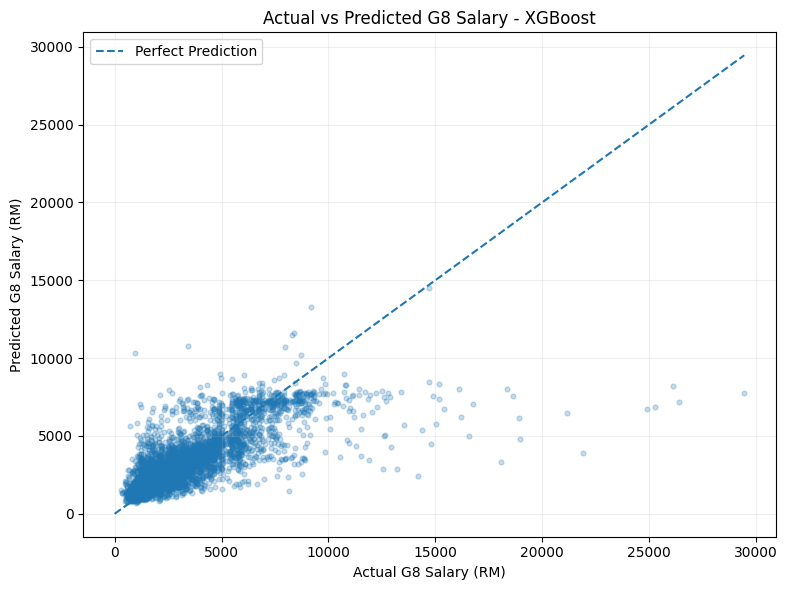

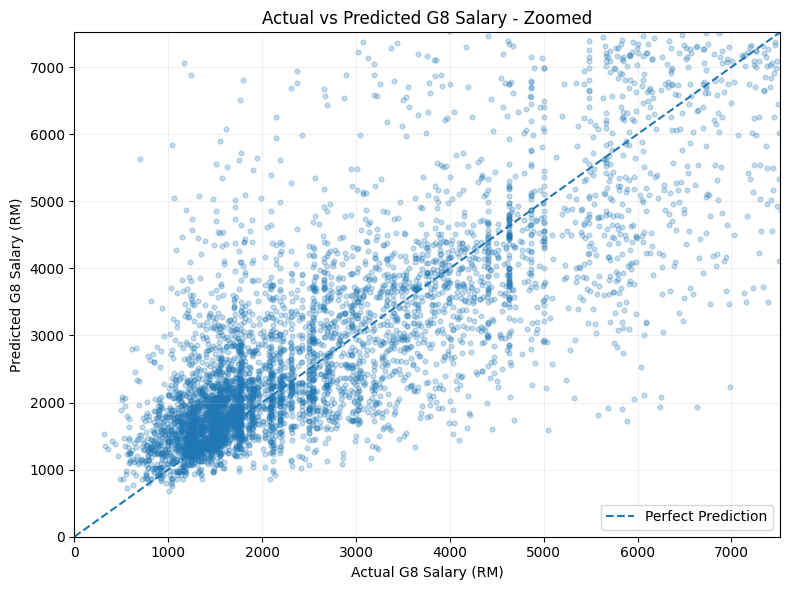

Test observations: 5485
Zoom limit (95th percentile): RM 7518.13


In [20]:

# Step 5.1: Actual vs Predicted Salary

import matplotlib.pyplot as plt
from pathlib import Path

# Create a dataframe for prediction analysis
prediction_df = pd.DataFrame({
    "Actual_G8": y_test.to_numpy(),
    "Predicted_G8": y_pred_xgb_test
})

# Create output directory
output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

# Plot 1: All test observations
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    prediction_df["Actual_G8"],
    prediction_df["Predicted_G8"],
    alpha=0.25,
    s=12
)

max_salary = max(
    prediction_df["Actual_G8"].max(),
    prediction_df["Predicted_G8"].max()
)

ax.plot(
    [0, max_salary],
    [0, max_salary],
    linestyle="--",
    label="Perfect Prediction"
)

ax.set_xlabel("Actual G8 Salary (RM)")
ax.set_ylabel("Predicted G8 Salary (RM)")
ax.set_title("Actual vs Predicted G8 Salary - XGBoost")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(output_dir / "actual_vs_predicted_full.png", dpi=300)
plt.show()

# Plot 2: Zoom into the typical salary range
zoom_limit = prediction_df["Actual_G8"].quantile(0.95)

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    prediction_df["Actual_G8"],
    prediction_df["Predicted_G8"],
    alpha=0.25,
    s=12
)

ax.plot(
    [0, zoom_limit],
    [0, zoom_limit],
    linestyle="--",
    label="Perfect Prediction"
)

ax.set_xlim(0, zoom_limit)
ax.set_ylim(0, zoom_limit)

ax.set_xlabel("Actual G8 Salary (RM)")
ax.set_ylabel("Predicted G8 Salary (RM)")
ax.set_title("Actual vs Predicted G8 Salary - Zoomed")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(output_dir / "actual_vs_predicted_zoomed.png", dpi=300)
plt.show()

print("Test observations:", len(prediction_df))
print("Zoom limit (95th percentile): RM",
      round(zoom_limit, 2))



### Step 5.2: Prediction Error Analysis by Salary Group

Evaluate prediction errors across different actual salary ranges to identify potential overestimation and underestimation patterns.


In [21]:

# Step 5.2: Prediction Error Analysis by Salary Group

# Calculate prediction errors
prediction_df["Error"] = (
    prediction_df["Predicted_G8"] - prediction_df["Actual_G8"]
)

prediction_df["Absolute_Error"] = (
    prediction_df["Error"].abs()
)

# Define salary groups using actual G8 salary
salary_bins = [0, 2000, 4000, 6000, 10000, np.inf]

salary_labels = [
    "Below RM2,000",
    "RM2,000–4,000",
    "RM4,000–6,000",
    "RM6,000–10,000",
    "RM10,000+"
]

prediction_df["Salary_Group"] = pd.cut(
    prediction_df["Actual_G8"],
    bins=salary_bins,
    labels=salary_labels,
    right=False
)

# Calculate error statistics for each salary group
salary_error_summary = (
    prediction_df
    .groupby("Salary_Group", observed=True)
    .agg(
        Count=("Actual_G8", "size"),
        Mean_Actual=("Actual_G8", "mean"),
        Mean_Predicted=("Predicted_G8", "mean"),
        Bias=("Error", "mean"),
        MAE=("Absolute_Error", "mean")
    )
    .reset_index()
)

print("Prediction Error Analysis by Salary Group:")
display(salary_error_summary.round(2))

# Overall error statistics
print("\nOverall Prediction Error:")
print("Mean Error (Bias): RM",
      round(prediction_df["Error"].mean(), 2))

print("Mean Absolute Error: RM",
      round(prediction_df["Absolute_Error"].mean(), 2))

print("Total test observations:",
      len(prediction_df))

print("Observations assigned to salary groups:",
      salary_error_summary["Count"].sum())


Prediction Error Analysis by Salary Group:


,Salary_Group,Count,Mean_Actual,Mean_Predicted,Bias,MAE
0,"Below RM2,000",2554,1417.85,1889.209961,471.36,546.43
1,"RM2,000–4,000",1612,2846.05,2976.250000,130.20,747.06
2,"RM4,000–6,000",769,4915.07,4521.279785,-393.79,1040.26
3,"RM6,000–10,000",476,7423.15,6247.669922,-1175.48,1532.76
4,"RM10,000+",74,13992.00,6565.759766,-7426.24,7426.24



Overall Prediction Error:
Mean Error (Bias): RM 0.34
Mean Absolute Error: RM 853.04
Total test observations: 5485
Observations assigned to salary groups: 5485



### Step 5.3: SHAP Explainability

#### Step 5.3.1: Global Feature Importance

Use SHAP TreeExplainer to identify the most influential features in the final XGBoost model.


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP values shape: (500, 59)
Number of features: 59

Top 15 Important Encoded Features:


,Feature,Mean_Abs_SHAP
0,nominal__Occupation_Group_Professionals,540.020020
1,ordinal__Educational_Attainment,426.040009
2,numerical__Age,396.720001
3,nominal__Industry_Section_O,210.929993
4,nominal__Industry_Section_P,165.649994
5,nominal__Occupation_Group_Technicians and Asso...,155.929993
6,nominal__Sex_1,131.539993
7,nominal__Occupation_Group_Managers,128.649994
8,nominal__State_10,104.180000
9,nominal__Strata_1,103.169998


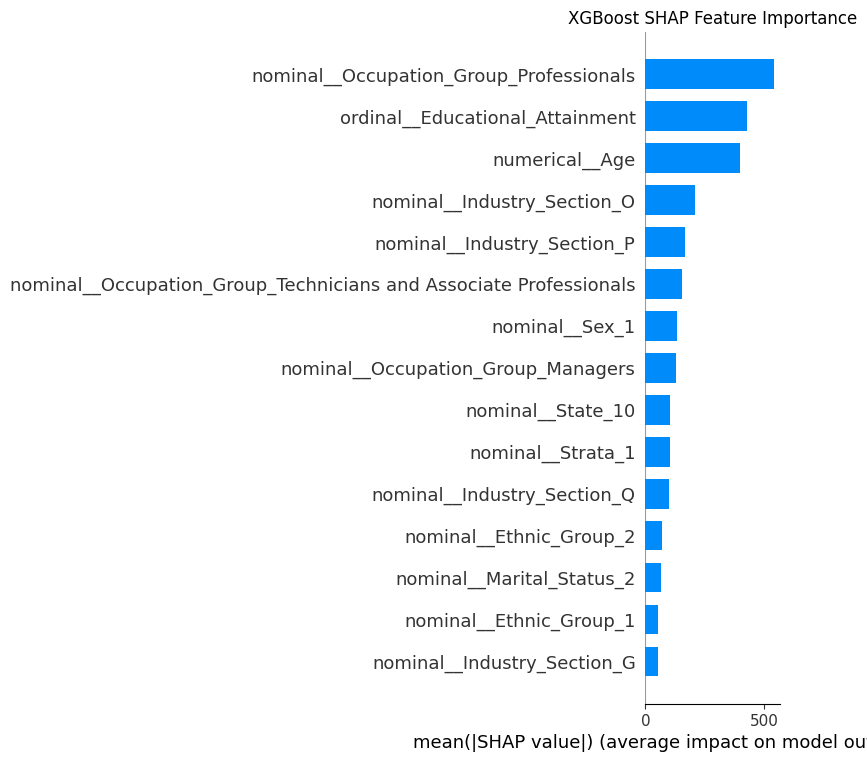

In [22]:

# Step 5.3.1: SHAP Global Feature Importance

import shap
import matplotlib.pyplot as plt

# 1. Select 500 test observations for SHAP analysis
rng = np.random.default_rng(42)

sample_idx = rng.choice(
    X_test_final.shape[0],
    size=500,
    replace=False
)

X_shap = X_test_final[sample_idx]

# 2. Create SHAP TreeExplainer
shap_explainer = shap.TreeExplainer(final_xgb_model)

# 3. Calculate SHAP values
shap_values = shap_explainer.shap_values(X_shap)

# 4. Obtain encoded feature names
shap_feature_names = (
    final_preprocessor.get_feature_names_out()
)

print("SHAP values shape:", shap_values.shape)
print("Number of features:", len(shap_feature_names))

assert shap_values.shape == (
    len(sample_idx),
    len(shap_feature_names)
)

# 5. Calculate global feature importance
shap_importance = pd.DataFrame({
    "Feature": shap_feature_names,
    "Mean_Abs_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values("Mean_Abs_SHAP", ascending=False)
    .reset_index(drop=True)
)

print("\nTop 15 Important Encoded Features:")
display(shap_importance.head(15).round(2))

# 6. Prepare feature values for plotting
X_shap_plot = (
    X_shap.toarray()
    if hasattr(X_shap, "toarray")
    else np.asarray(X_shap)
)

# 7. Plot SHAP global feature importance
shap.summary_plot(
    shap_values,
    X_shap_plot,
    feature_names=shap_feature_names,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title("XGBoost SHAP Feature Importance")

plt.savefig(
    output_dir / "shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



#### Step 5.3.2: SHAP Beeswarm Plot

Visualize the direction and distribution of SHAP values to examine how encoded features influence the XGBoost salary predictions.


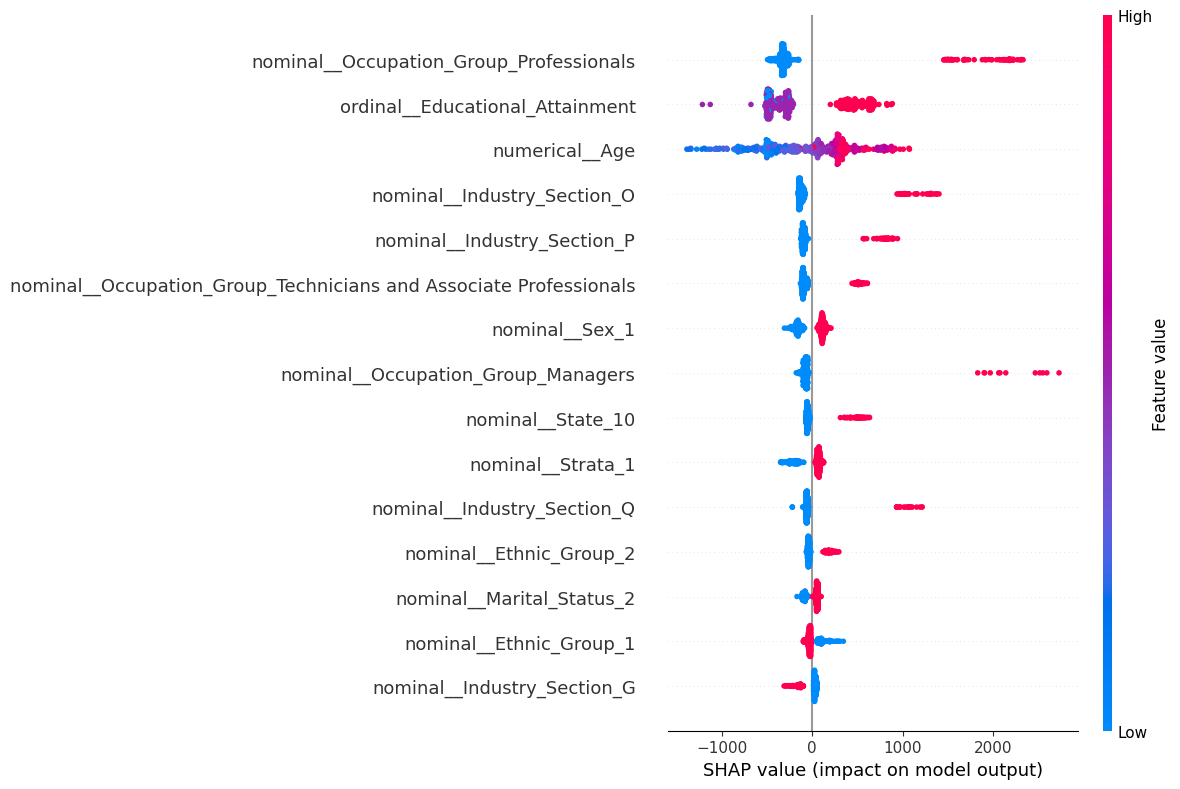

SHAP Beeswarm Plot generated successfully.


In [23]:

# Step 5.3.2: SHAP Beeswarm Plot

import matplotlib.pyplot as plt
import shap

# Plot SHAP beeswarm
shap.summary_plot(
    shap_values,
    X_shap_plot,
    feature_names=shap_feature_names,
    plot_type="dot",
    max_display=15,
    plot_size=(12, 8),
    show=False
)

# Save the figure
plt.savefig(
    output_dir / "shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP Beeswarm Plot generated successfully.")



#### Step 5.3.3: Grouped SHAP Feature Importance

Aggregate SHAP values from one-hot encoded features to the original variable level to compare the overall contributions of the nine predictor variables.


Feature Group Verification:
--------------------------
State: 16 encoded features
Strata: 2 encoded features
Sex: 2 encoded features
Ethnic_Group: 4 encoded features
Marital_Status: 4 encoded features
Occupation_Group: 10 encoded features
Industry_Section: 19 encoded features
Educational_Attainment: 1 encoded features
Age: 1 encoded features

Number of original variables: 9
Number of encoded features grouped: 59

Grouped SHAP Feature Importance:


,Original_Variable,Mean_Abs_SHAP_RM
0,Occupation_Group,683.48
1,Industry_Section,469.72
2,Educational_Attainment,426.04
3,Age,396.72
4,Sex,153.92
5,State,153.53
6,Ethnic_Group,120.27
7,Strata,112.37
8,Marital_Status,70.08



SHAP Contribution Verification:
------------------------------
Maximum SHAP summation difference: 0.0
SHAP grouping verification passed.


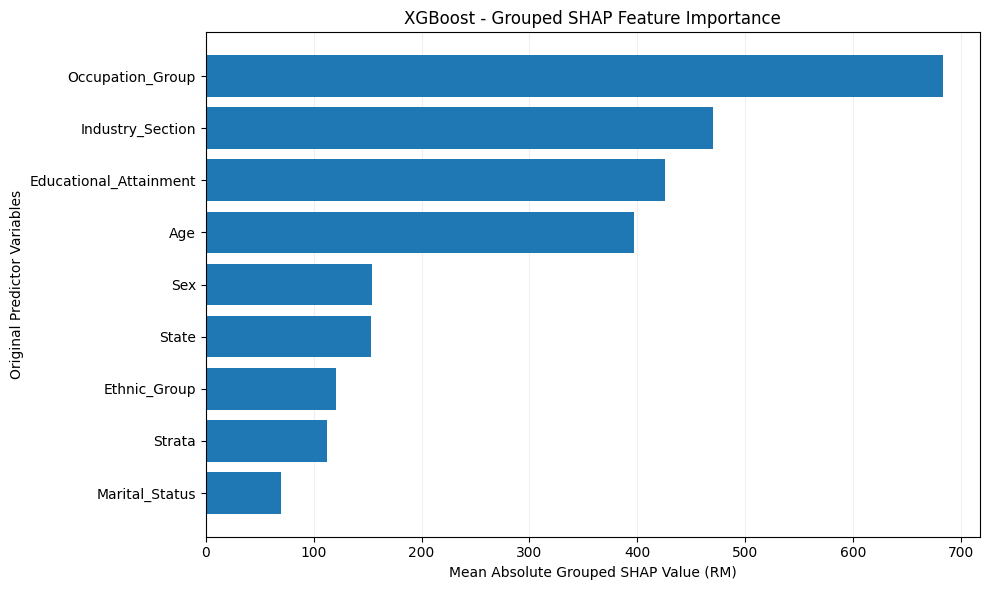


Grouped SHAP analysis completed successfully.
Figure saved to: ../results/shap_grouped_importance.png


In [25]:

# ==================================================
# Step 5.3.3: Grouped SHAP Feature Importance
# ==================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. Convert SHAP values to float64
# --------------------------------------------------

shap_values_64 = np.asarray(
    shap_values,
    dtype=np.float64
)

feature_names = [
    str(name) for name in shap_feature_names
]

# Verify dimensions
assert shap_values_64.ndim == 2
assert shap_values_64.shape[1] == len(feature_names)

# --------------------------------------------------
# 2. Define original variable groups
# --------------------------------------------------

nominal_groups = [
    "State",
    "Strata",
    "Sex",
    "Ethnic_Group",
    "Marital_Status",
    "Occupation_Group",
    "Industry_Section"
]

feature_group_indices = {}

# Group one-hot encoded variables
for col in nominal_groups:

    prefix = f"nominal__{col}_"

    indices = [
        i for i, name in enumerate(feature_names)
        if name.startswith(prefix)
    ]

    feature_group_indices[col] = indices

# Add ordinal variable
feature_group_indices["Educational_Attainment"] = [
    i for i, name in enumerate(feature_names)
    if name == "ordinal__Educational_Attainment"
]

# Add numerical variable
feature_group_indices["Age"] = [
    i for i, name in enumerate(feature_names)
    if name == "numerical__Age"
]

# --------------------------------------------------
# 3. Verify feature grouping
# --------------------------------------------------

all_indices = [
    i
    for indices in feature_group_indices.values()
    for i in indices
]

# Check that every original variable has features
for col, indices in feature_group_indices.items():
    assert len(indices) > 0, f"No features found for {col}"

# Check that all encoded features are assigned once
assert sorted(all_indices) == list(
    range(len(feature_names))
)

print("Feature Group Verification:")
print("--------------------------")

for col, indices in feature_group_indices.items():
    print(f"{col}: {len(indices)} encoded features")

print("\nNumber of original variables:",
      len(feature_group_indices))

print("Number of encoded features grouped:",
      len(all_indices))

# --------------------------------------------------
# 4. Calculate grouped SHAP values
# --------------------------------------------------

# Sum SHAP contributions for each original variable
grouped_shap = pd.DataFrame({
    col: shap_values_64[:, indices].sum(axis=1)
    for col, indices in feature_group_indices.items()
})

# Calculate mean absolute SHAP contribution
grouped_importance = (
    grouped_shap
    .abs()
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

grouped_importance.columns = [
    "Original_Variable",
    "Mean_Abs_SHAP_RM"
]

print("\nGrouped SHAP Feature Importance:")
display(grouped_importance.round(2))

# --------------------------------------------------
# 5. Verify SHAP contribution consistency
# --------------------------------------------------

# Sum grouped SHAP contributions per observation
grouped_total = (
    grouped_shap.sum(axis=1).to_numpy()
)

# Sum original encoded SHAP contributions
original_total = shap_values_64.sum(axis=1)

# Calculate maximum numerical difference
max_difference = np.max(
    np.abs(grouped_total - original_total)
)

print("\nSHAP Contribution Verification:")
print("------------------------------")

print("Maximum SHAP summation difference:",
      max_difference)

# Verify totals are numerically consistent
np.testing.assert_allclose(
    grouped_total,
    original_total,
    rtol=1e-10,
    atol=1e-8
)

print("SHAP grouping verification passed.")

# --------------------------------------------------
# 6. Plot grouped SHAP feature importance
# --------------------------------------------------

# Sort for horizontal bar chart
plot_data = grouped_importance.sort_values(
    "Mean_Abs_SHAP_RM",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    plot_data["Original_Variable"],
    plot_data["Mean_Abs_SHAP_RM"]
)

ax.set_xlabel(
    "Mean Absolute Grouped SHAP Value (RM)"
)

ax.set_ylabel("Original Predictor Variables")

ax.set_title(
    "XGBoost - Grouped SHAP Feature Importance"
)

ax.grid(
    axis="x",
    alpha=0.2
)

ax.set_axisbelow(True)

plt.tight_layout()

# --------------------------------------------------
# 7. Save the figure
# --------------------------------------------------

output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "shap_grouped_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nGrouped SHAP analysis completed successfully.")
print("Figure saved to:",
      output_dir / "shap_grouped_importance.png")



### Step 5.4: Five-Fold Cross-Validation

Evaluate the stability of Gradient Boosting and XGBoost using five-fold cross-validation on the original training dataset.

Preprocessing is fitted separately within each fold to prevent data leakage. Model performance is compared using MAE, RMSE, and R².


In [26]:

# ==================================================
# Step 5.4: Five-Fold Cross-Validation
# ==================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# --------------------------------------------------
# 1. Define cross-validation strategy
# --------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# --------------------------------------------------
# 2. Define models for comparison
# --------------------------------------------------

cv_models = {
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

# --------------------------------------------------
# 3. Define evaluation metrics
# --------------------------------------------------

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# --------------------------------------------------
# 4. Run five-fold cross-validation
# --------------------------------------------------

cv_records = []

for model_name, model in cv_models.items():

    print(f"\nRunning 5-Fold CV: {model_name}")

    # Fit preprocessing within each fold
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(model))
    ])

    # Cross-validation on training data only
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    # Convert negative error scores into positive values
    mae_scores = -scores["test_MAE"]
    rmse_scores = -scores["test_RMSE"]
    r2_scores = scores["test_R2"]

    # Store results from each fold
    for i in range(5):
        cv_records.append({
            "Model": model_name,
            "Fold": i + 1,
            "MAE": mae_scores[i],
            "RMSE": rmse_scores[i],
            "R2": r2_scores[i]
        })

# --------------------------------------------------
# 5. Display performance for each fold
# --------------------------------------------------

cv_results = pd.DataFrame(cv_records)

print("\nFive-Fold Cross-Validation Results:")
display(cv_results.round(4))

# --------------------------------------------------
# 6. Calculate mean and standard deviation
# --------------------------------------------------

cv_summary = (
    cv_results
    .groupby("Model")
    .agg(
        Mean_MAE=("MAE", "mean"),
        SD_MAE=("MAE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        SD_RMSE=("RMSE", "std"),
        Mean_R2=("R2", "mean"),
        SD_R2=("R2", "std")
    )
    .reset_index()
    .sort_values("Mean_MAE")
)

print("\nCross-Validation Summary:")
display(cv_summary.round(4))

# --------------------------------------------------
# 7. Verify cross-validation results
# --------------------------------------------------

assert len(cv_results) == 10
assert cv_results.groupby("Model")["Fold"].nunique().eq(5).all()
assert np.isfinite(
    cv_results[["MAE", "RMSE", "R2"]].to_numpy()
).all()

print("\nCross-validation completed successfully.")
print("Original training observations:", len(X_train))
print("Models evaluated:", len(cv_models))
print("Folds per model:", cv.get_n_splits())



Running 5-Fold CV: Gradient Boosting

Running 5-Fold CV: XGBoost

Five-Fold Cross-Validation Results:


,Model,Fold,MAE,RMSE,R2
0,Gradient Boosting,1,851.4204,1460.8297,0.6081
1,Gradient Boosting,2,877.8557,1880.3117,0.5093
2,Gradient Boosting,3,851.2153,1480.6932,0.6001
3,Gradient Boosting,4,863.2858,1508.1065,0.5880
4,Gradient Boosting,5,867.7176,1806.4317,0.5416
5,XGBoost,1,851.3363,1459.6864,0.6087
6,XGBoost,2,876.2529,1885.7439,0.5064
7,XGBoost,3,850.2312,1482.0945,0.5993
8,XGBoost,4,859.4192,1463.5854,0.6120
9,XGBoost,5,870.1055,1822.7080,0.5333



Cross-Validation Summary:


,Model,Mean_MAE,SD_MAE,Mean_RMSE,SD_RMSE,Mean_R2,SD_R2
1,XGBoost,861.469,11.4708,1622.7636,212.6359,0.5719,0.0487
0,Gradient Boosting,862.299,11.3307,1627.2746,199.6973,0.5694,0.0424



Cross-validation completed successfully.
Original training observations: 21940
Models evaluated: 2
Folds per model: 5



### Step 5.5: SHAP Robustness Check

#### Step 5.5.1: Global SHAP Importance Using the Full Test Set

Calculate SHAP values for all 5,485 test observations and compare grouped feature importance rankings with the previous 500-sample analysis.


Full SHAP shape: (5485, 59)

Full-Test Grouped SHAP Importance:


,Original_Variable,SHAP_Full_5485
0,Occupation_Group,725.02
1,Industry_Section,493.53
2,Educational_Attainment,433.55
3,Age,394.98
4,Sex,153.26
5,State,148.03
6,Ethnic_Group,117.66
7,Strata,115.02
8,Marital_Status,71.27



SHAP Robustness Comparison:


,Original_Variable,SHAP_500,SHAP_Full_5485,Rank_500,Rank_Full
0,Occupation_Group,683.48,725.02,1,1
1,Industry_Section,469.72,493.53,2,2
2,Educational_Attainment,426.04,433.55,3,3
3,Age,396.72,394.98,4,4
4,Sex,153.92,153.26,5,5
5,State,153.53,148.03,6,6
6,Ethnic_Group,120.27,117.66,7,7
7,Strata,112.37,115.02,8,8
8,Marital_Status,70.08,71.27,9,9



Spearman Rank Correlation: 1.0


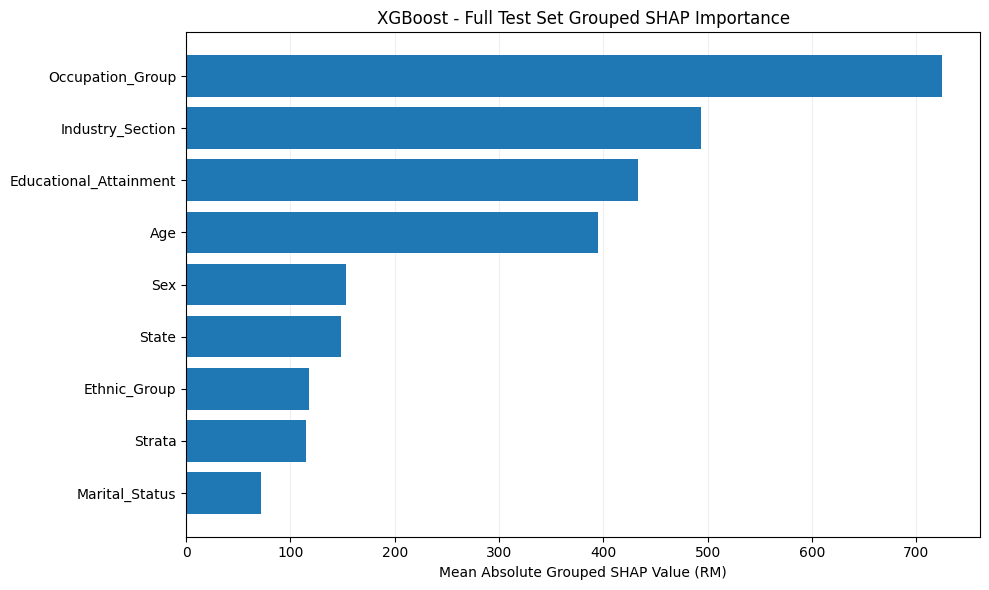


Full-test SHAP analysis completed.
Observations explained: 5485
Original variables: 9


In [27]:

# ==================================================
# Step 5.5.1: Full-Test SHAP Robustness Check
# ==================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Calculate SHAP for the full test set
# --------------------------------------------------

shap_values_full = np.asarray(
    shap_explainer.shap_values(X_test_final),
    dtype=np.float64
)

print("Full SHAP shape:", shap_values_full.shape)

assert shap_values_full.shape == (
    len(y_test),
    len(shap_feature_names)
)

# --------------------------------------------------
# 2. Aggregate SHAP into the 9 original variables
# --------------------------------------------------

grouped_shap_full = pd.DataFrame({
    col: shap_values_full[:, indices].sum(axis=1)
    for col, indices in feature_group_indices.items()
})

# Verify grouped SHAP consistency
np.testing.assert_allclose(
    grouped_shap_full.sum(axis=1).to_numpy(),
    shap_values_full.sum(axis=1),
    rtol=1e-10,
    atol=1e-8
)

# Calculate full-test grouped importance
full_importance = (
    grouped_shap_full
    .abs()
    .mean()
    .sort_values(ascending=False)
    .rename_axis("Original_Variable")
    .reset_index(name="SHAP_Full_5485")
)

print("\nFull-Test Grouped SHAP Importance:")
display(full_importance.round(2))

# --------------------------------------------------
# 3. Compare 500 samples with 5,485 samples
# --------------------------------------------------

importance_500 = grouped_importance[
    ["Original_Variable", "Mean_Abs_SHAP_RM"]
].rename(
    columns={"Mean_Abs_SHAP_RM": "SHAP_500"}
)

shap_comparison = importance_500.merge(
    full_importance,
    on="Original_Variable",
    how="inner",
    validate="one_to_one"
)

# Calculate importance ranks
shap_comparison["Rank_500"] = (
    shap_comparison["SHAP_500"]
    .rank(ascending=False, method="min")
    .astype(int)
)

shap_comparison["Rank_Full"] = (
    shap_comparison["SHAP_Full_5485"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Sort by full-test importance
shap_comparison = (
    shap_comparison
    .sort_values("Rank_Full")
    .reset_index(drop=True)
)

print("\nSHAP Robustness Comparison:")
display(shap_comparison.round(2))

# --------------------------------------------------
# 4. Calculate rank correlation
# --------------------------------------------------

rank_correlation = shap_comparison[
    ["Rank_500", "Rank_Full"]
].corr(method="spearman").iloc[0, 1]

print("\nSpearman Rank Correlation:",
      round(rank_correlation, 4))

# --------------------------------------------------
# 5. Plot full-test SHAP importance
# --------------------------------------------------

plot_data = full_importance.sort_values(
    "SHAP_Full_5485",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data["Original_Variable"],
    plot_data["SHAP_Full_5485"]
)

ax.set_xlabel(
    "Mean Absolute Grouped SHAP Value (RM)"
)

ax.set_title(
    "XGBoost - Full Test Set Grouped SHAP Importance"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    output_dir / "shap_full_test_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 6. Final verification
# --------------------------------------------------

assert len(full_importance) == 9
assert len(shap_comparison) == 9
assert np.isfinite(shap_values_full).all()

print("\nFull-test SHAP analysis completed.")
print("Observations explained:", len(shap_values_full))
print("Original variables:", len(full_importance))



#### Step 5.5.2: High-Income SHAP Analysis

Examine SHAP contributions for employees earning RM10,000 or above. Compare grouped feature importance between high-income and other test observations, and investigate the model's underestimation of high salaries.


High-Income Prediction Summary
------------------------------
High-income observations: 74
Mean actual salary: RM 13992.00
Mean predicted salary: RM 6565.76
Mean prediction bias: RM -7426.24

High-Income SHAP Comparison:


,Original_Variable,Full_Test_Importance,High_Income_Importance,Other_Income_Importance,High_Income_Mean_SHAP
0,Occupation_Group,725.02,1800.27,710.31,1741.04
1,Age,394.98,724.71,390.47,581.19
2,Industry_Section,493.53,648.55,491.41,415.84
3,Educational_Attainment,433.55,628.11,430.89,504.36
4,State,148.03,222.61,147.01,63.60
5,Ethnic_Group,117.66,173.10,116.90,77.76
6,Sex,153.26,167.03,153.07,55.41
7,Strata,115.02,91.73,115.33,85.83
8,Marital_Status,71.27,67.63,71.32,23.74


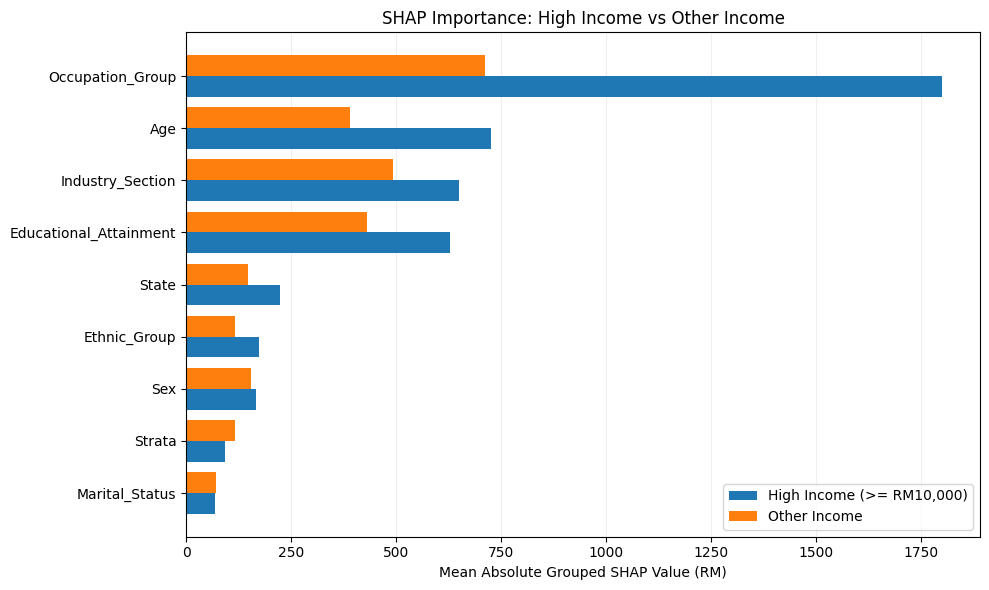


High-income SHAP analysis completed successfully.


In [28]:

# ==================================================
# Step 5.5.2: High-Income SHAP Analysis
# ==================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Verify that predictions and SHAP use the same test order
np.testing.assert_allclose(
    prediction_df["Actual_G8"].to_numpy(),
    y_test.to_numpy()
)

assert len(grouped_shap_full) == len(prediction_df)

# 2. Identify high-income employees (G8 >= RM10,000)
high_income_mask = (
    prediction_df["Actual_G8"].to_numpy() >= 10000
)

# Separate grouped SHAP values
shap_high = grouped_shap_full.loc[high_income_mask]
shap_other = grouped_shap_full.loc[~high_income_mask]

# 3. Check prediction bias for high-income employees
high_income_predictions = prediction_df.loc[high_income_mask]

mean_actual = high_income_predictions["Actual_G8"].mean()
mean_predicted = high_income_predictions["Predicted_G8"].mean()
high_income_bias = mean_predicted - mean_actual

print("High-Income Prediction Summary")
print("------------------------------")
print("High-income observations:", len(shap_high))
print(f"Mean actual salary: RM {mean_actual:.2f}")
print(f"Mean predicted salary: RM {mean_predicted:.2f}")
print(f"Mean prediction bias: RM {high_income_bias:.2f}")

# 4. Compare original-variable SHAP importance
high_income_shap_summary = pd.DataFrame({
    "Original_Variable": grouped_shap_full.columns,
    "Full_Test_Importance": grouped_shap_full.abs().mean().values,
    "High_Income_Importance": shap_high.abs().mean().values,
    "Other_Income_Importance": shap_other.abs().mean().values,
    "High_Income_Mean_SHAP": shap_high.mean().values
})

high_income_shap_summary = (
    high_income_shap_summary
    .sort_values("High_Income_Importance", ascending=False)
    .reset_index(drop=True)
)

print("\nHigh-Income SHAP Comparison:")
display(high_income_shap_summary.round(2))

# 5. Plot SHAP importance comparison
plot_data = high_income_shap_summary.sort_values(
    "High_Income_Importance"
)

y_positions = np.arange(len(plot_data))

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    y_positions - 0.2,
    plot_data["High_Income_Importance"],
    height=0.4,
    label="High Income (>= RM10,000)"
)

ax.barh(
    y_positions + 0.2,
    plot_data["Other_Income_Importance"],
    height=0.4,
    label="Other Income"
)

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["Original_Variable"])

ax.set_xlabel("Mean Absolute Grouped SHAP Value (RM)")
ax.set_title("SHAP Importance: High Income vs Other Income")

ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    output_dir / "shap_high_income_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Final verification
assert len(shap_high) + len(shap_other) == len(y_test)
assert np.isfinite(
    high_income_shap_summary.select_dtypes(include="number")
).to_numpy().all()

print("\nHigh-income SHAP analysis completed successfully.")
